In [1]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from datasets import load_dataset

dataset = load_dataset("Bitext/Bitext-customer-support-llm-chatbot-training-dataset")
X = dataset['train']

In [2]:
corpus = X['instruction'][:2000]
corpus

['question about cancelling order {{Order Number}}',
 'i have a question about cancelling oorder {{Order Number}}',
 'i need help cancelling puchase {{Order Number}}',
 'I need to cancel purchase {{Order Number}}',
 'I cannot afford this order, cancel purchase {{Order Number}}',
 'can you help me cancel order {{Order Number}}?',
 'I can no longer afford order {{Order Number}}, cancel it',
 'I am trying to cancel purchase {{Order Number}}',
 'I have got to cancel purchase {{Order Number}}',
 'i need help canceling purchase {{Order Number}}',
 'i dont know what to do to cancel order {{Order Number}}',
 'I have a problem with cancelling purchase {{Order Number}}',
 'problem with canceling purchase {{Order Number}}',
 'can you help me canceling order {{Order Number}}?',
 'help  me canceling purchase {{Order Number}}',
 'can you help me cancel purchase {{Order Number}}?',
 'what do I have to do to cancel purchase {{Order Number}}?',
 'I bought the same item twice, cancel order {{Order Numbe

# Generate Embeddings and train model on embeddings.

In [3]:
import sys
sys.path.append("../src")
from embeddings import embed_tickets
from kmeans import CustomKmeansPlusPlus

X_embed = embed_tickets(corpus)

model = CustomKmeansPlusPlus(k=8, max_iters=100, random_state=42)
model.fit(X_embed)
X_embed.shape

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Batches:   0%|          | 0/143 [00:00<?, ?it/s]

(2000, 384)

# Calculate new Silhouette Score

In [4]:
from sklearn.metrics import silhouette_score

k_values = [3, 5, 8, 12, 16, 20, 25]

for k in k_values:
    model = CustomKmeansPlusPlus(k=k, max_iters=50, random_state=42)
    model.fit(X_embed)
    # inertias.append(model.inertia_)
    tfidf_silhouette_score = silhouette_score(X_embed, model.labels)
    print(tfidf_silhouette_score)

print(f"Layer 2 (Embeddings) Silhouette Score: {tfidf_silhouette_score:.4f}")
print("Compare this to your Layer 1 TF-IDF score of 0.1765!")

0.2555494010448456
0.2711915373802185
0.2508499026298523
0.25515010952949524
0.216274693608284
0.21596388518810272
0.2249062955379486
Layer 2 (Embeddings) Silhouette Score: 0.2249
Compare this to your Layer 1 TF-IDF score of 0.1765!


# Visualising Dense space

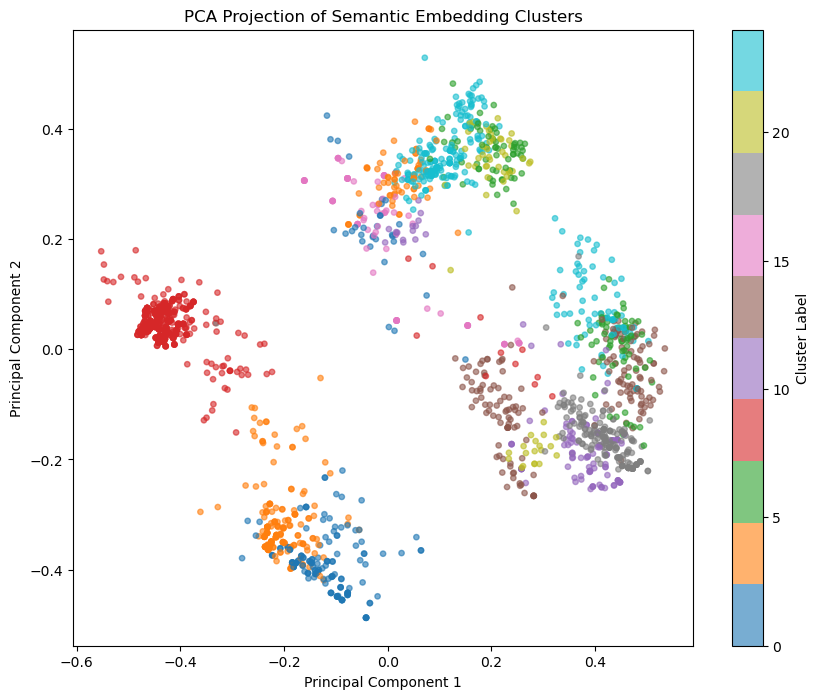

In [5]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=42)
X_pca_dense = pca.fit_transform(X_embed)

plt.figure(figsize=(10, 8))
scatter = plt.scatter(X_pca_dense[:, 0], X_pca_dense[:, 1], 
                      c=model.labels, cmap='tab10', alpha=0.6, s=15)

plt.title("PCA Projection of Semantic Embedding Clusters")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.colorbar(scatter, label="Cluster Label")
plt.show()

# Exporting sklearn's KMeans model with entire 27000 corpus
## _This is an Anchor file. Exporting "model" (CustomKMeansPlusPlus) or "km" (sklearn's KMeans model) decides performance_

In [6]:
corpus = X['instruction']
len(corpus)

26872

In [7]:
from embeddings import embed_tickets

X_embed = embed_tickets(corpus)
X_embed.shape

Batches:   0%|          | 0/1920 [00:00<?, ?it/s]

(26872, 384)

In [8]:
from sklearn.cluster import KMeans

km = KMeans(
    n_init=10,
    n_clusters=12,
    tol=1e-4,
    max_iter=300,
    init='k-means++',
    random_state=42)

km.fit(X_embed)

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",12
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",10
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary `.",42
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'


In [9]:
from vector_store import TicketIndexer

indexer = TicketIndexer(vector_dim=X_embed.shape[1], use_hnsw=True)
indexer.build_index(X_embed)

In [10]:
import pickle

# Pickle dump model
"""
Change the model to either "model" or "km" in the following pickle.dump line
"""
with open('../data/processed/kmeans_model.pkl', 'wb') as file:
    pickle.dump(km, file)

print("Model file dumped Successfully ✅")

# Numpy save corpus
np.save('../data/processed/embeddings.npy', X_embed)
print("Embeddings saved Successfully ✅")


# Pickle dump corpus
with open('../data/processed/corpus.pkl', 'wb') as file:
    pickle.dump(corpus, file)

print("Corpus file dumped Successfully ✅")

Model file dumped Successfully ✅
Embeddings saved Successfully ✅
Corpus file dumped Successfully ✅
